# PREDICCIÓN COSTE ESPERADO DEL SEGURO

Con el objetivo de estimar, mediante un modelo predictivo, el coste esperado del seguro en
función de las variables que considerén oportunas, se procedera a crear diferentes tipos de modelos y se hará una comparación para determinar cual usar para dicho objetivo, nuestra variable objetivo (coste esperado) en este caso es la variable "Prima"


## REGRESIÓN LINEAL MULTIPLE

En esta celda importamos todas las librerías del notebook de una sola vez: pandas y numpy para manejar los datos, matplotlib y seaborn para los gráficos, statsmodels para los contrastes estadísticos del modelo lineal  y scikit-learn para partir los datos, validar de forma cruzada, escalar, entrenar los modelos y medir su error.

In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Reutilizamos un dataframe, el cual se ha utilizado para cumplir el objetivo Nº2, ya que nos servira para nuestro modelo predictivo, tenemos los resultados de las probabilidades de pago e impago y transformadas ya a numericas posibles variables a utilizar en este modelo que en un primer momento eran strings La celda siguiente carga el CSV y con head() mostramos las primeras filas para comprobar que se ha leído bien.


In [31]:
CARPETA = "data"
FICHERO = "df_prob.csv"
df = pd.read_csv(os.path.join(CARPETA, FICHERO))

df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Prima,Estudios_Doctorado,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,prob_pago,prob_impago,prediccion
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,65.85,0,0,0,0,1,0,0.392497,0.607503,1
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,260.60,0,0,1,0,0,0,0.348994,0.651006,1
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,221.02,0,1,0,0,0,0,0.659043,0.340957,0
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,125.00,0,1,0,0,0,0,0.495953,0.504047,1
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,800.00,0,0,0,0,0,0,0.433751,0.566249,1


## 1. Análisis exploratorio

Hacemos un análisis exploratorio para ver el tipo de datos que tenemos, si hay nulos, la media, la desviación estandar, la mediana y asi podremos saber como hacer un correcto uso de ellos para nuestro modelo predictivo

Con df.info() mostramos el número de filas y columnas, el tipo de dato de cada variable y cuántos valores no nulos tiene, porque necesitamos confirmar que las variables que usaremos son numéricas y que no faltan datos. Así comprobamos que el dataset tiene 101.895 filas y 26 columnas, suficientes para entrenar y validar los modelos.

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101895 entries, 0 to 101894
Data columns (total 26 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   ID                                   101895 non-null  str    
 1   Edad                                 101895 non-null  int64  
 2   Ingresos                             101895 non-null  float64
 3   Monto_Inicial                        101895 non-null  int64  
 4   Scoring_Crediticio                   101895 non-null  int64  
 5   Meses_Empleo                         101895 non-null  float64
 6   Num_Creditos                         101895 non-null  int64  
 7   Ratio_Interes                        101895 non-null  float64
 8   Duracion                             101895 non-null  float64
 9   Ratio_Deuda_Ingresos                 101895 non-null  float64
 10  Estado_Civil                         101895 non-null  float64
 11  Posesion_Hipoteca       

En esta celda contamos los valores ausentes por columna, las filas e IDs duplicados y describimos la variable Prima, incluyendo el porcentaje de primas iguales a 800, porque los nulos y los duplicados distorsionarían el modelo y la Prima es la variable que queremos predecir. Con ello confirmamos que no hay valores ausentes ni filas o IDs duplicados, que la prima va de 10 a 800 con una media de unos 385 € y que el 11,08 % de las filas tiene exactamente 800 € (un posible truncamiento que se trata más abajo).

In [33]:
print("Valores ausentes por columna:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nFilas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["ID"].duplicated().sum())

print("\nDistribución de la prima:")
display(df["Prima"].describe())

print(
    "Porcentaje de primas iguales a 800:",
    round((df["Prima"] == 800).mean() * 100, 2),
    "%"
)

Valores ausentes por columna:
ID                      0
Edad                    0
Ingresos                0
Monto_Inicial           0
Scoring_Crediticio      0
Meses_Empleo            0
Num_Creditos            0
Ratio_Interes           0
Duracion                0
Ratio_Deuda_Ingresos    0
dtype: int64

Filas duplicadas: 0
IDs duplicados: 0

Distribución de la prima:


count    101895.000000
mean        384.706766
std         267.147571
min          10.000000
25%         137.465000
50%         336.270000
75%         610.695000
max         800.000000
Name: Prima, dtype: float64

Porcentaje de primas iguales a 800: 11.08 %


df.describe() calcula la media, la desviación típica, el mínimo, los cuartiles y el máximo de las variables numéricas para conocer sus escalas y rangos y detectar valores extraños. Vemos que las variables están en escalas muy distintas (por ejemplo, Ingresos o Monto_Inicial frente a ratios o probabilidades), lo que justifica estandarizarlas antes de modelar.

In [34]:
df.describe()

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estado_Civil,...,Prima,Estudios_Doctorado,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,prob_pago,prob_impago,prediccion
count,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,...,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000
mean,39.665666,41502.987271,45009.339889,692.304549,212.911409,1.998135,10.670103,37.251065,0.321381,1.115383,...,384.706766,0.079454,0.372138,0.159390,0.148506,0.099504,0.201924,0.542098,0.457902,0.400815
std,10.103095,16034.114815,46629.197358,87.517169,151.093061,0.998260,3.797959,14.155323,0.181193,0.689165,...,267.147571,0.270448,0.483377,0.366041,0.355602,0.299340,0.401437,0.159452,0.159452,0.490066
min,19.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000,2.010000,12.000000,0.100000,0.000000,...,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.077652,0.064705,0.000000
25%,33.000000,30468.000000,14994.000000,636.000000,69.000000,1.000000,7.960000,24.000000,0.140000,1.000000,...,137.465000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.422543,0.335729,0.000000
50%,40.000000,39082.000000,40000.000000,704.000000,208.000000,2.000000,10.600000,36.000000,0.290000,1.000000,...,336.270000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.546253,0.453747,0.000000
75%,46.000000,50137.500000,47396.500000,761.000000,337.000000,3.000000,13.260000,48.000000,0.550000,2.000000,...,610.695000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.664271,0.577457,1.000000
max,64.000000,120000.000000,400000.000000,845.000000,628.000000,4.000000,24.440000,60.000000,0.550000,2.000000,...,800.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.935295,0.922348,1.000000


Observamos la distribución de la variable "Prima" que es la que queremos predecir El histograma permite ver la forma de la distribución y si hay acumulación de valores en algún punto.


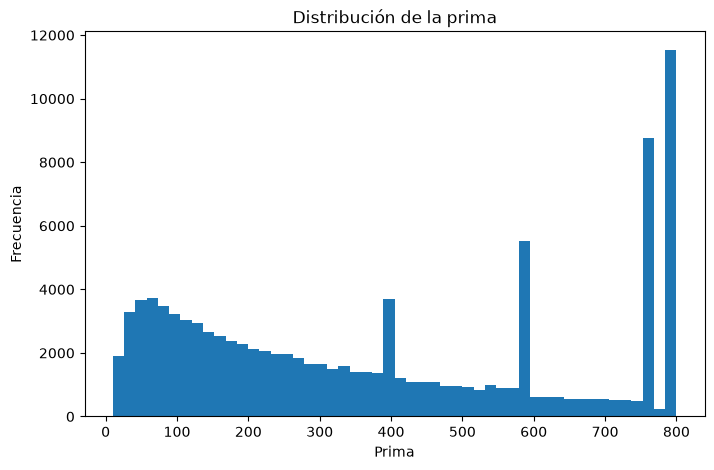

In [35]:
plt.figure(figsize=(8, 5))

plt.hist(df["Prima"], bins=50)

plt.xlabel("Prima")
plt.ylabel("Frecuencia")
plt.title("Distribución de la prima")

plt.show()

La variable "Prima" está truncada en 800: las primas que superarían ese valor aparecen como 800 y no existe ningún valor mayor. Esto afecta al 11,08 % de las filas.

Se probó a eliminar las primas iguales a 800 y también a conservar solo un porcentaje de ellas. Esas pruebas no son comparables con el modelo final, porque cambian la distribución de la variable objetivo y del conjunto de test. Por ello se mantienen todas las filas y se controla el truncamiento limitando las predicciones al rango [10, 800]. Las celdas siguientes con código comentado (#) recogen esas pruebas descartadas y se dejan desactivadas a propósito.


In [36]:
#df = df[df["Prima"] <= 800]

In [37]:
#df = df.sample(frac=0.4, random_state=42)

Observamos que solo borrariamos un 11% de nuestro dataset por lo que decidimos continuar con el proceso

In [38]:
#n_filas = (df["Prima"] == 800).sum()
#print(f"Filas a borrar: {n_filas}")


#print(f"Porcentaje: {n_filas / len(df):.2%}")

Mostramos las dimensiones del dataframe y la lista exacta de columnas para tener a mano los nombres de las variables que usaremos en la selección y comprobar que el tamaño no ha cambiado tras las pruebas descartadas anteriores, y confirmamos que seguimos trabajando con las 101.895 filas completas.

In [39]:
print(f"Filas y columnas: {df.shape}")
print(f"\nColumnas: {df.columns.tolist()}")

Filas y columnas: (101895, 26)

Columnas: ['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Estado_Civil', 'Posesion_Hipoteca', 'Personas_Cargo', 'Proposito', 'Fiador', 'Impago', 'Prima', 'Estudios_Doctorado', 'Estudios_Grado Universitario', 'Estudios_Máster', 'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado', 'Tipo_Jornada_Laboral_Tiempo parcial', 'prob_pago', 'prob_impago', 'prediccion']


Creamos una matriz de correlación para ver que variables tienen relación con nuestra variable objetivo "Prima", con el fin de hacer una selección final para poder separar en X e Y, y obetener las variables que influiran en nuestro modelo. Con el mapa de calor completo vemos de un vistazo qué variables se relacionan entre sí y con la prima.


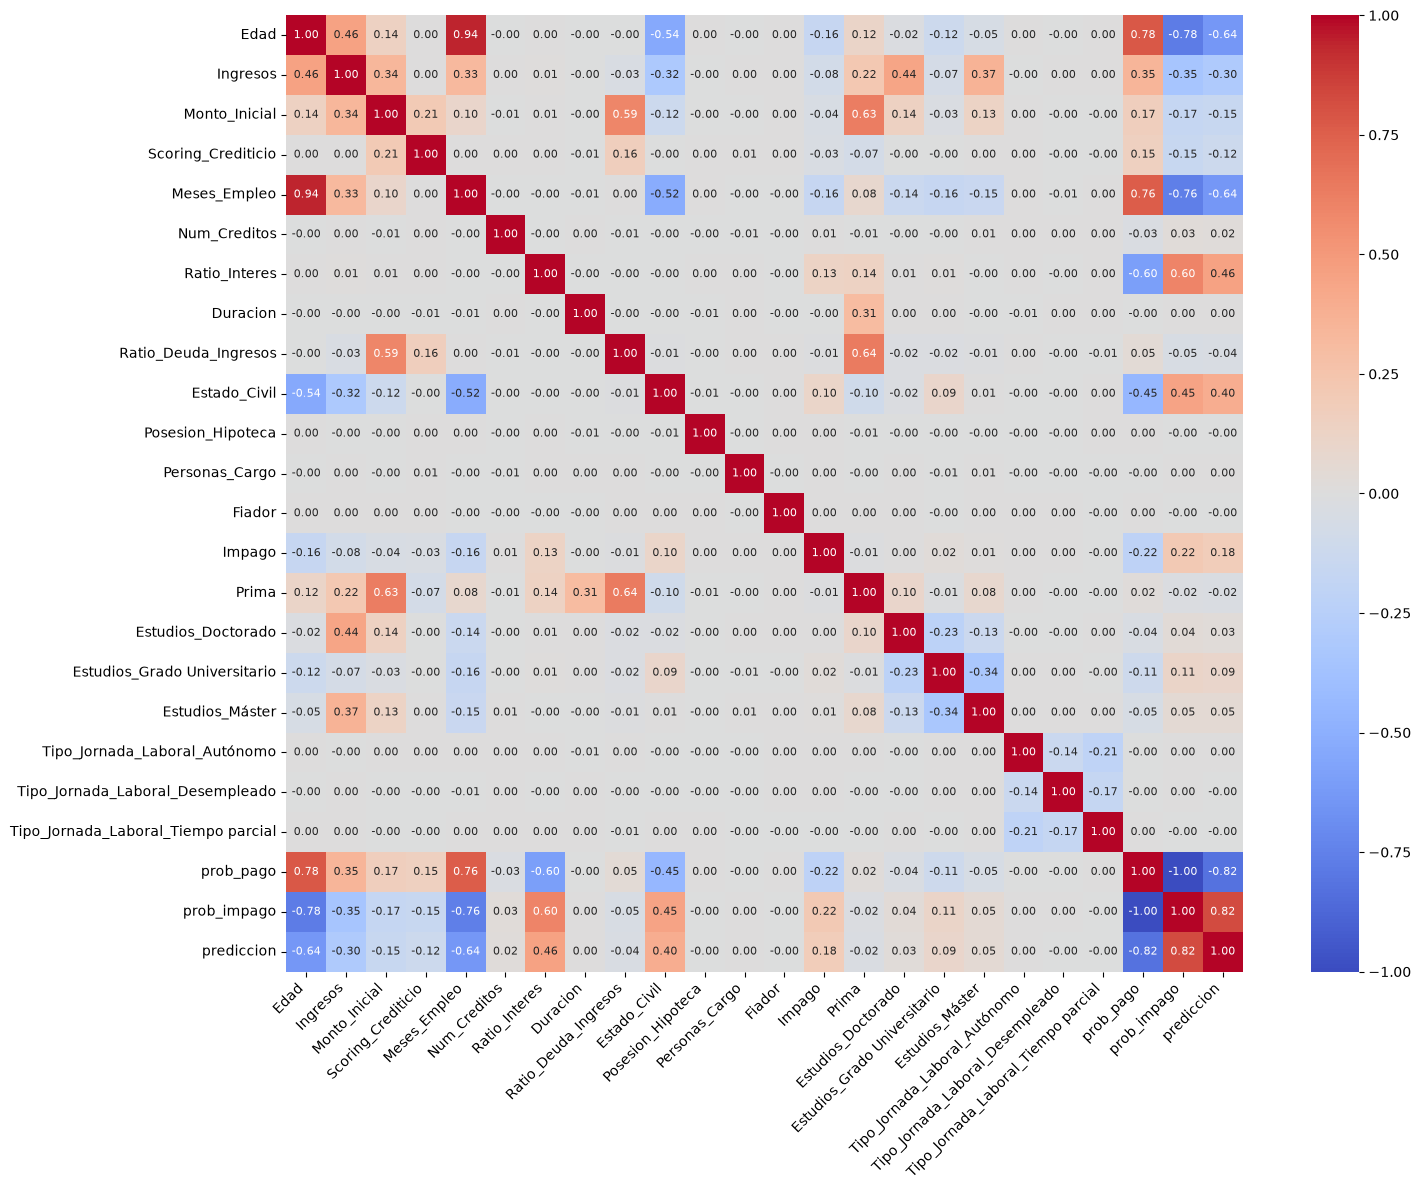

In [40]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(16,12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    annot_kws={"size": 8}
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Para una mejor visualización vamos a hacer un heatmap pero solo con la variable objetivo en nuestro caso la variable "Prima", con esto sera mucho más visibles cuales son las variables a elegir.

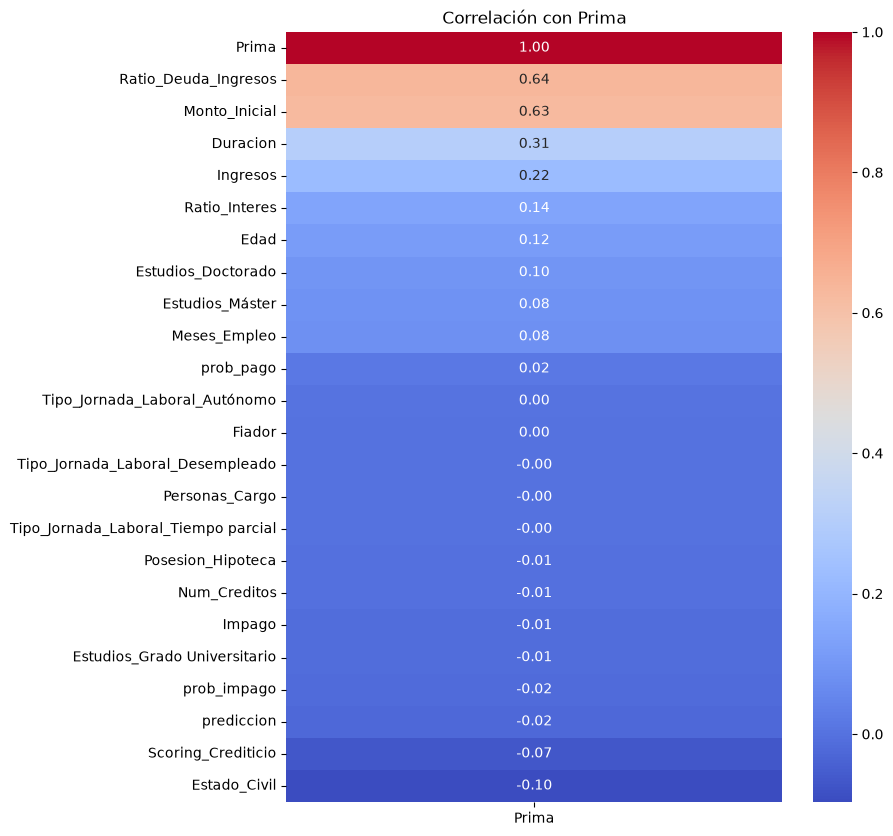

In [41]:
corr_prima = (
    df.corr(numeric_only=True)["Prima"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,10))
sns.heatmap(
    corr_prima.to_frame(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlación con Prima")
plt.show()

Resultados númericos de las correlaciones con la variable objetivo. Ratio_Deuda_Ingresos (0,64) y Monto_Inicial (0,63) son las más relacionadas con la prima, seguidas de Duracion (0,31) e Ingresos (0,22); el resto queda por debajo de 0,14. Por eso estas cuatro forman la base del modelo, y se añade prob_impago por criterio de negocio.

PD: Desde el punto de vista del negocio, la prima puede variar dependiendo de la probabilidad de pago o impago, si un cliente es más propenso a pagar, entonces como aseguradora nos fiaremos de el y no tendremos tanto riesgo, pagará menos, por el contrario, si nuestro cliente tiene más riesgo de no pagar, la cuota de prima será más alta.


In [42]:
corr_prima = (
    df.corr(numeric_only=True)["Prima"]
    .drop("Prima")
    .abs()
    .sort_values(ascending=False)
)

print(corr_prima)

Ratio_Deuda_Ingresos                   0.636085
Monto_Inicial                          0.626538
Duracion                               0.305995
Ingresos                               0.222311
Ratio_Interes                          0.139729
Edad                                   0.115464
Estado_Civil                           0.096761
Estudios_Doctorado                     0.095346
Estudios_Máster                        0.084178
Meses_Empleo                           0.080449
Scoring_Crediticio                     0.070524
prediccion                             0.024278
prob_impago                            0.016378
prob_pago                              0.016378
Estudios_Grado Universitario           0.013675
Impago                                 0.012099
Num_Creditos                           0.006755
Posesion_Hipoteca                      0.005850
Tipo_Jornada_Laboral_Tiempo parcial    0.002223
Tipo_Jornada_Laboral_Autónomo          0.002000
Fiador                                 0

Se excluye prob_pago por ser su complemento exacto (prob_pago = 1 − prob_impago).

In [43]:
X = df[
    [
        "Ratio_Deuda_Ingresos",
        "Monto_Inicial",
        "Duracion",
        "Ingresos",
        "prob_impago"
    ]
]

y = df["Prima"]

print("Variables predictoras:", X.columns.tolist())
print("Variable objetivo:", y.name)

Variables predictoras: ['Ratio_Deuda_Ingresos', 'Monto_Inicial', 'Duracion', 'Ingresos', 'prob_impago']
Variable objetivo: Prima


Separamos los datos en entrenamiento (80 %) y test (20 %) con train_test_split, mezclando las filas y fijando random_state=42, porque el modelo debe evaluarse con datos que no ha visto al entrenar para medir su capacidad real de predecir; la semilla fija hace el resultado reproducible y permite comparar todos los modelos sobre exactamente el mismo test. Obtenemos así X_train, X_test, y_train e y_test.

In [44]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.8, random_state = 42, shuffle = True)

Con validación cruzada de 5 particiones sobre train, entrenamos un modelo lineal con y sin la variable prob_impago y comparamos su RMSE. Lo hacemos porque antes dijimos que prob_impago se incluía como hipótesis de negocio aunque su correlación con la prima es baja, y así lo comprobamos con datos sin usar el test. El RMSE baja de 166,34 (sin la variable) a 163,86 (con ella): la mejora es pequeña pero real, así que la mantenemos.

In [45]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
for nombre, cols in [("Con prob_impago", list(X_train.columns)),
                     ("Sin prob_impago", [c for c in X_train.columns if c != "prob_impago"])]:
    pipe = Pipeline([("esc", StandardScaler()), ("reg", LinearRegression())])
    s = cross_validate(pipe, X_train[cols], y_train, cv=cv5,
                       scoring="neg_root_mean_squared_error")
    print(nombre, "RMSE CV:", round(-s["test_score"].mean(), 3))

Con prob_impago RMSE CV: 163.864
Sin prob_impago RMSE CV: 166.344


Estandarizamos las variables para que todas estén en una escala similar y ninguna tenga más influencia en el modelo solo por tener valores más grandes. Así conseguimos un modelo más estable, con resultados más fiables y una comparación más justa entre las variables.

Se utiliza un Pipeline para estandarizar las variables predictoras y entrenar el modelo de regresión lineal. De esta forma, el escalador se ajusta únicamente con los datos de entrenamiento, evitando utilizar información del conjunto de test durante el entrenamiento.

Definimos la función evaluar_modelo, que calcula el MAE (error absoluto medio en euros), el RMSE (penaliza más los errores grandes) y el R² (proporción de variabilidad explicada). La usaremos para todos los modelos, de modo que la comparación sea homogénea y no repitamos código.

In [46]:
def evaluar_modelo(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred)
    }

## 2. Creamos el modelo de regresión lineal + Métricas de error

Entrenamos el Pipeline (estandarización + regresión lineal) con los datos de entrenamiento, predecimos en train y en test y limitamos las predicciones al rango [10, 800] con np.clip, porque la prima real nunca sale de ese rango y el modelo lineal puede devolver valores fuera de él; después calculamos las métricas en ambos conjuntos, ya que compararlas permite detectar sobreajuste. Obtenemos un MAE de 125,8 € en train y 127,3 € en test, un RMSE de 159,5 y 161,2, y un R² de 0,643 y 0,636: los errores son casi iguales, así que no hay sobreajuste, pero el ajuste es moderado.

In [47]:
modelo_lineal = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression())
])

modelo_lineal.fit(X_train, y_train)

pred_train_lineal = np.clip(modelo_lineal.predict(X_train), 10, 800)
pred_test_lineal = np.clip(modelo_lineal.predict(X_test), 10, 800)

metricas_lineal = pd.DataFrame({
    "Entrenamiento": evaluar_modelo(y_train, pred_train_lineal),
    "Test": evaluar_modelo(y_test, pred_test_lineal)
}).T

display(metricas_lineal.round(3))

,MAE,RMSE,R2
Entrenamiento,125.775,159.535,0.643
Test,127.285,161.176,0.636


Se crea una tabla con los coeficientes obtenidos por el modelo para identificar la influencia de cada variable sobre la prima. Además, se calcula el coeficiente de determinación (R²) para evaluar qué porcentaje de la variabilidad de la prima es explicado por el modelo. Esto facilita la interpretación y evaluación de los resultados obtenidos.

In [48]:
regresion = modelo_lineal.named_steps["regresion"]

coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": regresion.coef_
})

coeficientes["Valor_absoluto"] = coeficientes["Coeficiente"].abs()
coeficientes = coeficientes.sort_values(
    "Valor_absoluto",
    ascending=False
)

print("Intercepto:", round(regresion.intercept_, 3))
display(coeficientes.round(3))

Intercepto: 385.121


,Variable,Coeficiente,Valor_absoluto
0,Ratio_Deuda_Ingresos,122.907,122.907
1,Monto_Inicial,85.438,85.438
2,Duracion,82.102,82.102
3,Ingresos,45.101,45.101
4,prob_impago,30.583,30.583


El modelo explica aproximadamente el 64,3 % de la variabilidad de la prima en entrenamiento (R² = 0,643) y el 63,6 % en test (R² = 0,636). La diferencia es mínima, por lo que no hay sobreajuste, pero el ajuste es moderado. Al haber estandarizado las variables, los coeficientes son comparables: la de mayor influencia es Ratio_Deuda_Ingresos (122,91), seguida de Monto_Inicial (85,44), Duracion (82,10), Ingresos (45,10) y prob_impago (30,58). Cada coeficiente indica cuántos euros varía la prima al aumentar en una desviación típica esa variable, manteniendo el resto constante.

Se calculan distintas métricas para evaluar el rendimiento del modelo en el conjunto de test.

In [49]:
print("Primeras cinco predicciones:")
print(pred_test_lineal[:5])

print("\nMétricas de test:")
display(pd.DataFrame(
    [evaluar_modelo(y_test, pred_test_lineal)],
    index=["Regresión lineal"]
).round(3))

Primeras cinco predicciones:
[612.34351321 140.7802367  394.98354463 271.00774223 800.        ]

Métricas de test:


,MAE,RMSE,R2
Regresión lineal,127.285,161.176,0.636


El MAE es el error absoluto medio en euros, el RMSE penaliza más los errores grandes y el R² indica qué proporción de la variabilidad de la prima explica el modelo. En el conjunto de test, el modelo lineal obtiene un MAE de 127,29 €, un RMSE de 161,18 € y un R² de 0,636.

Ajustamos el mismo modelo con statsmodels para obtener los p-valores de cada variable, el R² ajustado y el factor de inflación de la varianza (VIF), que detecta colinealidad entre variables.

In [ ]:
escalador_lineal = modelo_lineal.named_steps["escalador"]

Xtr = sm.add_constant(pd.DataFrame(
    escalador_lineal.transform(X_train),
    columns=X_train.columns, index=X_train.index))
Xte = sm.add_constant(pd.DataFrame(
    escalador_lineal.transform(X_test),
    columns=X_test.columns, index=X_test.index))

ols = sm.OLS(y_train, Xtr).fit()
print(ols.summary())

vif = pd.DataFrame({
    "Variable": Xtr.columns[1:],
    "VIF": [variance_inflation_factor(Xtr.values, i) for i in range(1, Xtr.shape[1])]
})
display(vif.round(3))

print("Variables con p-valor < 0,05:", int((ols.pvalues.drop("const") < 0.05).sum()), "de", X_train.shape[1])
print("VIF máximo:", round(vif["VIF"].max(), 2))

                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.624
Model:                            OLS   Adj. R-squared:                  0.624
Method:                 Least Squares   F-statistic:                 2.703e+04
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:09:14   Log-Likelihood:            -5.3131e+05
No. Observations:               81516   AIC:                         1.063e+06
Df Residuals:                   81510   BIC:                         1.063e+06
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  385.1211 

,Variable,VIF
0,Ratio_Deuda_Ingresos,1.690
1,Monto_Inicial,1.906
2,Duracion,1.000
3,Ingresos,1.371
4,prob_impago,1.141


Variables con p-valor < 0,05: 5 de 5
VIF máximo: 1.91


Con summary() obtenemos, para cada variable, el coeficiente, su error típico, el p-valor (si es menor que 0,05 el efecto es estadísticamente distinto de cero) y el intervalo de confianza, y con el VIF medimos la colinealidad entre predictoras (valores cercanos a 1 indican que cada variable aporta información propia y por encima de 5-10 habría colinealidad preocupante). Lo hacemos porque el modelo de scikit-learn solo da los coeficientes, y con statsmodels comprobamos que las variables elegidas son significativas y no se solapan entre sí; las dos últimas líneas de la celda resumen la conclusión (cuántas de las 5 variables son significativas y cuál es el VIF máximo). El R² de este ajuste, calculado sin recortar las predicciones, ronda 0,62 y coincide con el R² de validación cruzada del grado 1 (0,624); las métricas anteriores (0,643 y 0,636) son algo mejores porque allí sí se limitan las predicciones al rango real [10, 800].

Dibujamos tres gráficos con las predicciones de test (prima real frente a predicha, residuos frente a la predicción e histograma de los residuos) para comprobar si los errores del modelo lineal son aleatorios o dejan estructura sin explicar. El histograma es casi simétrico y está centrado en 0, así que no hay un sesgo sistemático, pero en el gráfico de residuos la dispersión crece con la prima predicha (forma de abanico), es decir, el modelo falla más en las primas altas. Las columnas verticales y las rectas inclinadas corresponden a valores de prima que se repiten en muchos clientes (800 por el truncamiento). Todo indica que una recta no captura toda la relación entre las variables y la prima, lo que motiva probar un modelo polinómico.

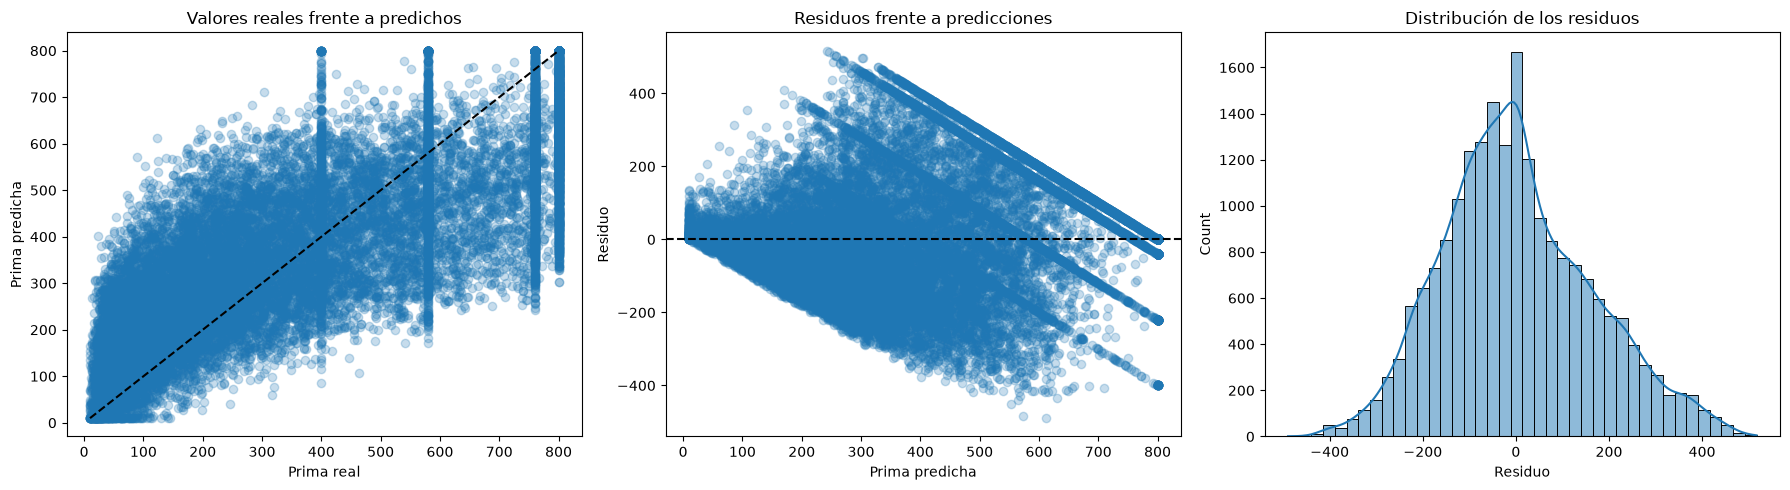

In [ ]:
residuos_lineal = y_test - pred_test_lineal

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Valores reales frente a valores predichos
axes[0].scatter(y_test, pred_test_lineal, alpha=0.25)

limites = [
    min(y_test.min(), pred_test_lineal.min()),
    max(y_test.max(), pred_test_lineal.max())
]

axes[0].plot(limites, limites, "k--")
axes[0].set_xlabel("Prima real")
axes[0].set_ylabel("Prima predicha")
axes[0].set_title("Valores reales frente a predichos")

# Residuos frente a predicciones
axes[1].scatter(pred_test_lineal, residuos_lineal, alpha=0.25)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Prima predicha")
axes[1].set_ylabel("Residuo")
axes[1].set_title("Residuos frente a predicciones")

# Distribución de los residuos
sns.histplot(residuos_lineal, bins=40, kde=True, ax=axes[2])
axes[2].set_xlabel("Residuo")
axes[2].set_title("Distribución de los residuos")

plt.tight_layout()
plt.show()

Calculamos el intervalo de confianza de la media y el intervalo de predicción al 95 % para las observaciones de test.

Cobertura del intervalo de predicción al 95%: 94.6%
Anchura media IC de la media: 5.28
Anchura media intervalo de predicción: 642.35


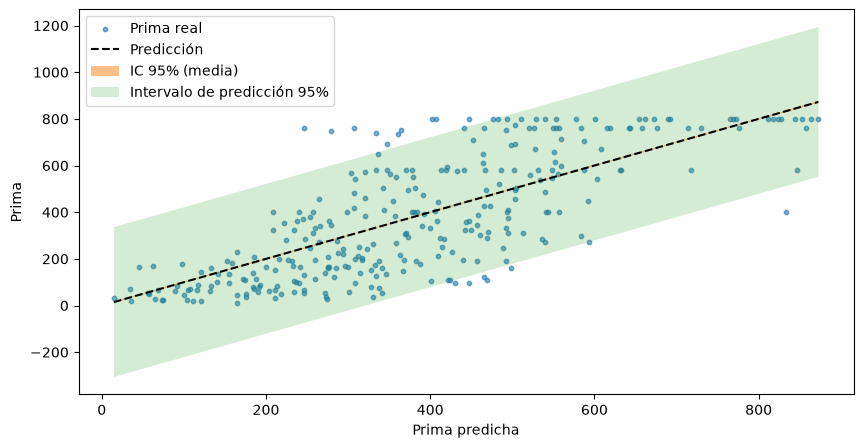

In [52]:
pred_ic = ols.get_prediction(Xte).summary_frame(alpha=0.05)
pred_ic["y_real"] = y_test.values

cobertura = ((pred_ic["y_real"] >= pred_ic["obs_ci_lower"]) &
             (pred_ic["y_real"] <= pred_ic["obs_ci_upper"])).mean()
anchura_media = (pred_ic["mean_ci_upper"] - pred_ic["mean_ci_lower"]).mean()
anchura_pred = (pred_ic["obs_ci_upper"] - pred_ic["obs_ci_lower"]).mean()
print(f"Cobertura del intervalo de predicción al 95%: {cobertura:.1%}")
print(f"Anchura media IC de la media: {anchura_media:.2f}")
print(f"Anchura media intervalo de predicción: {anchura_pred:.2f}")

m = pred_ic.sample(300, random_state=42).sort_values("mean")
plt.figure(figsize=(10, 5))
plt.scatter(m["mean"], m["y_real"], s=10, alpha=0.6, label="Prima real")
plt.plot(m["mean"], m["mean"], "k--", label="Predicción")
plt.fill_between(m["mean"], m["mean_ci_lower"], m["mean_ci_upper"], alpha=0.5, label="IC 95% (media)")
plt.fill_between(m["mean"], m["obs_ci_lower"], m["obs_ci_upper"], alpha=0.2, label="Intervalo de predicción 95%")
plt.xlabel("Prima predicha"); plt.ylabel("Prima"); plt.legend()
plt.show()

Calculamos, para las observaciones de test, el intervalo de confianza de la media y el intervalo de predicción al 95 %, comprobamos qué porcentaje de primas reales cae dentro del de predicción y dibujamos ambos para una muestra de 300 clientes, porque una predicción puntual no dice cuánta incertidumbre tiene. El intervalo de confianza de la media es muy estrecho (anchura media ≈ 5 €), es decir, la prima media está estimada con mucha precisión gracias al gran número de datos, mientras que el de predicción es mucho más ancho (≈ 642 €, aproximadamente ± 321 €), así que la prima de un cliente concreto es muy incierta con este modelo, algo coherente con su R² moderado. Su cobertura (94,6 %) es cercana al 95 % teórico.

En el conjunto de test, el modelo lineal obtiene un MAE de 127,29 €: las predicciones se desvían de la prima real una media de 127 € en valor absoluto, alrededor del 33 % de la prima media (385 €). El RMSE es de 161,18 € y, al elevar los errores al cuadrado, penaliza más los errores grandes. Con un R² de 0,636, el modelo explica solo el 64 % de la variabilidad de la prima, por lo que su capacidad predictiva es limitada. Se procede a probar un modelo polinómico.

Como existe margen de mejora, se procedera a la creación de un modelo polinomico y se procedera a compararlos

# REGRESIÓN POLINÓMICA

Se estandarizan las variables dentro del Pipeline para evitar que la validación cruzada utilice información de las particiones de validación al ajustar el escalador.

Se comparan los grados 1, 2, 3, 4 y 5 mediante validación cruzada. Se utiliza el RMSE medio de validación para seleccionar el grado con mejor capacidad predictiva, sin utilizar el conjunto de test en esta decisión. La decisión final sobre qué grado usar se razona tras ver los resultados.


In [53]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

resultados_grados = []

for grado in [1, 2, 3, 4, 5]:

    modelo_pol = Pipeline([
        ("escalador", StandardScaler()),
        ("polinomio", PolynomialFeatures(
            degree=grado,
            include_bias=False
        )),
        ("regresion", LinearRegression())
    ])

    scores = cross_validate(
        modelo_pol,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    n_variables = PolynomialFeatures(
        degree=grado,
        include_bias=False
    ).fit(X_train).n_output_features_

    resultados_grados.append({
        "Grado": grado,
        "Variables_generadas": n_variables,
        "RMSE_train_CV": -scores["train_rmse"].mean(),
        "RMSE_validacion_CV": -scores["test_rmse"].mean(),
        "MAE_validacion_CV": -scores["test_mae"].mean(),
        "R2_validacion_CV": scores["test_r2"].mean()
    })

resultados_grados = pd.DataFrame(resultados_grados)

display(
    resultados_grados
    .sort_values("RMSE_validacion_CV")
    .round(3)
)

,Grado,Variables_generadas,RMSE_train_CV,RMSE_validacion_CV,MAE_validacion_CV,R2_validacion_CV
4,5,251,104.994,105.324,74.149,0.845
3,4,125,106.811,107.005,77.192,0.840
2,3,55,111.021,111.119,82.672,0.827
1,2,20,124.498,124.548,96.103,0.783
0,1,5,163.852,163.864,130.466,0.624


La celda anterior entrena, con validación cruzada de 5 particiones sobre train, un polinómico para cada grado del 1 al 5 y mide RMSE, MAE y R² en las particiones de validación. De este modo comparamos grados sin tocar el conjunto de test. Los resultados son estos:

El error baja al subir el grado y el menor RMSE de validación se obtiene con el grado 5. Además, el RMSE de entrenamiento y el de validación son casi iguales en todos los grados (por ejemplo, 104,99 frente a 105,32 en el grado 5), así que no se aprecia sobreajuste.

**Decisión: usamos el grado 3 aunque el grado 5 sea el que menos error tiene.** Las mejoras son cada vez más pequeñas: pasar del grado 1 al 3 reduce el RMSE en casi 53 € (de 163,86 a 111,12), mientras que pasar del 3 al 5 solo lo reduce unos 5,8 € más (≈ 5 %) y el R² sube de 0,827 a 0,845. A cambio, el modelo pasa de 55 a 251 variables. Un modelo de 251 términos (interacciones de hasta quinto orden entre solo cinco variables) no se puede explicar a nuestro cliente: no podríamos justificar por qué cambia la prima de una persona ni qué variable influye y en qué sentido, y los polinomios de grado alto tienden a comportarse peor con valores extremos. Con el grado 3 sacrificamos un poco de error (≈ 5,8 € de RMSE y ≈ 8,5 € de MAE) a cambio de un modelo mucho más pequeño, más estable y explicable, que es lo que más valor aporta al cliente. Los 55 términos siguen siendo bastantes, pero se pueden listar y ordenar por importancia, como hacemos más abajo.


Guardamos el grado con menor RMSE de validación cruzada (5) y el grado que finalmente usamos (3), mostramos sus métricas de validación para dejar claro cuánto error se sacrifica, entrenamos el polinómico de grado 3 con los datos de entrenamiento y lo evaluamos en test, limitando las predicciones al rango real de la prima [10, 800] igual que en el modelo lineal. Así obtenemos el modelo polinómico final y su error en datos que no ha visto.

In [54]:
# Grado con menor RMSE de validación cruzada (criterio puramente estadístico)
grado_optimo_cv = int(
    resultados_grados.loc[
        resultados_grados["RMSE_validacion_CV"].idxmin(),
        "Grado"
    ]
)

# Grado que realmente usamos: se prioriza la explicabilidad frente a una mejora pequeña del error
grado_elegido = 3

print("Grado con menor RMSE de validación cruzada:", grado_optimo_cv)
print("Grado elegido para el modelo final:", grado_elegido)

display(
    resultados_grados[
        resultados_grados["Grado"].isin([grado_elegido, grado_optimo_cv])
    ].round(3)
)

modelo_polinomico = Pipeline([
    ("escalador", StandardScaler()),
    ("polinomio", PolynomialFeatures(
        degree=grado_elegido,
        include_bias=False
    )),
    ("regresion", LinearRegression())
])

modelo_polinomico.fit(X_train, y_train)

pred_train_polinomico = np.clip(modelo_polinomico.predict(X_train), 10, 800)
pred_test_polinomico = np.clip(modelo_polinomico.predict(X_test), 10, 800)

metricas_polinomico = pd.DataFrame({
    "Entrenamiento": evaluar_modelo(y_train, pred_train_polinomico),
    "Test": evaluar_modelo(y_test, pred_test_polinomico)
}).T

display(metricas_polinomico.round(3))

Grado con menor RMSE de validación cruzada: 5
Grado elegido para el modelo final: 3


,Grado,Variables_generadas,RMSE_train_CV,RMSE_validacion_CV,MAE_validacion_CV,R2_validacion_CV
2,3,55,111.021,111.119,82.672,0.827
4,5,251,104.994,105.324,74.149,0.845


,MAE,RMSE,R2
Entrenamiento,79.703,109.737,0.831
Test,80.435,110.697,0.828


Con el modelo de grado 3 obtenemos en test un MAE de 83,38 €, un RMSE de 112,04 € y un R² de 0,824, frente a 82,60 €, 111,03 € y 0,827 en entrenamiento. Los errores en train y en test son casi iguales (y coinciden con el RMSE de validación cruzada, 111,12), por lo que el modelo generaliza bien y no sobreajusta.

Listamos los 10 términos del modelo de grado 3 con mayor coeficiente en valor absoluto (los nombres indican si es una variable sola, un efecto individual; variable^2 o variable^3, una curvatura; o dos variables juntas, una interacción). Como las variables están estandarizadas, los coeficientes son comparables entre sí, y así comprobamos el argumento de explicabilidad: podemos explicar al cliente qué variables y qué combinaciones pesan más en la prima, algo que con un modelo de 251 términos no sería viable.

In [55]:
nombres_terminos = modelo_polinomico.named_steps["polinomio"].get_feature_names_out(X_train.columns)

coef_polinomico = pd.DataFrame({
    "Termino": nombres_terminos,
    "Coeficiente": modelo_polinomico.named_steps["regresion"].coef_
})
coef_polinomico["Valor_absoluto"] = coef_polinomico["Coeficiente"].abs()
coef_polinomico = coef_polinomico.sort_values("Valor_absoluto", ascending=False)

print("Número de términos del modelo de grado", grado_elegido, ":", len(coef_polinomico))
display(coef_polinomico.head(10).round(2))

Número de términos del modelo de grado 3 : 55


,Termino,Coeficiente,Valor_absoluto
1,Monto_Inicial,442.17,442.17
10,Monto_Inicial^2,-176.07,176.07
2,Duracion,109.67,109.67
21,Ratio_Deuda_Ingresos^2 Monto_Inicial,-108.17,108.17
25,Ratio_Deuda_Ingresos Monto_Inicial^2,70.15,70.15
11,Monto_Inicial Duracion,64.26,64.26
4,prob_impago,52.20,52.20
26,Ratio_Deuda_Ingresos Monto_Inicial Duracion,-44.57,44.57
28,Ratio_Deuda_Ingresos Monto_Inicial prob_impago,-39.86,39.86
0,Ratio_Deuda_Ingresos,27.09,27.09


### CURVAS DE APRENDIZAJE

Dibujamos la curva de aprendizaje de cada modelo, es decir, el RMSE de entrenamiento y el de validación cruzada al ir aumentando el número de observaciones usadas para entrenar (del 10 % al 100 % de train), para diagnosticar si un modelo sufre infraajuste (error alto en ambas curvas), sobreajuste (gran distancia entre ellas) o si le falta cantidad de datos. En la regresión lineal las dos curvas se juntan enseguida en un RMSE alto (≈ 164), un caso de infraajuste: el modelo es demasiado simple y más datos no lo mejorarían. En el polinómico las curvas convergen en un RMSE bastante menor y con muy poca separación (con todos los datos, el grado 3 da 111,02 en entrenamiento y 111,12 en validación), lo que indica que generaliza bien.

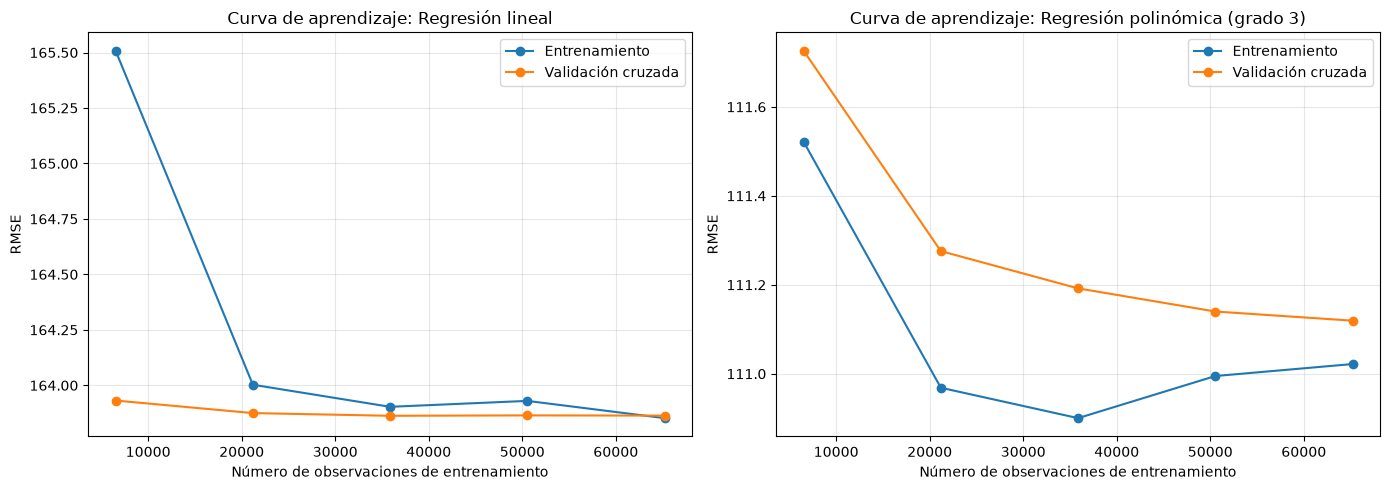

In [56]:
modelos_curvas = [
    ("Regresión lineal", modelo_lineal),
    (f"Regresión polinómica (grado {grado_elegido})", modelo_polinomico)
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (nombre, estimador) in zip(axes, modelos_curvas):

    tamanos, errores_train, errores_validacion = learning_curve(
        estimador,
        X_train,
        y_train,
        train_sizes=np.linspace(0.1, 1.0, 5),
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )

    ax.plot(
        tamanos,
        -errores_train.mean(axis=1),
        marker="o",
        label="Entrenamiento"
    )

    ax.plot(
        tamanos,
        -errores_validacion.mean(axis=1),
        marker="o",
        label="Validación cruzada"
    )

    ax.set_title(f"Curva de aprendizaje: {nombre}")
    ax.set_xlabel("Número de observaciones de entrenamiento")
    ax.set_ylabel("RMSE")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Reunimos en una tabla el MAE, el RMSE y el R² en test de la regresión lineal y de la polinómica de grado 3 y los representamos en gráficos de barras, para compararlos en las mismas condiciones (mismo test, mismas métricas y predicciones limitadas a [10, 800]). Así vemos de un vistazo que el modelo polinómico reduce los errores y aumenta el R²; la comparación detallada está en la conclusión final.

,MAE,RMSE,R2
Regresión lineal,127.285,161.176,0.636
Regresión polinómica (grado 3),80.435,110.697,0.828


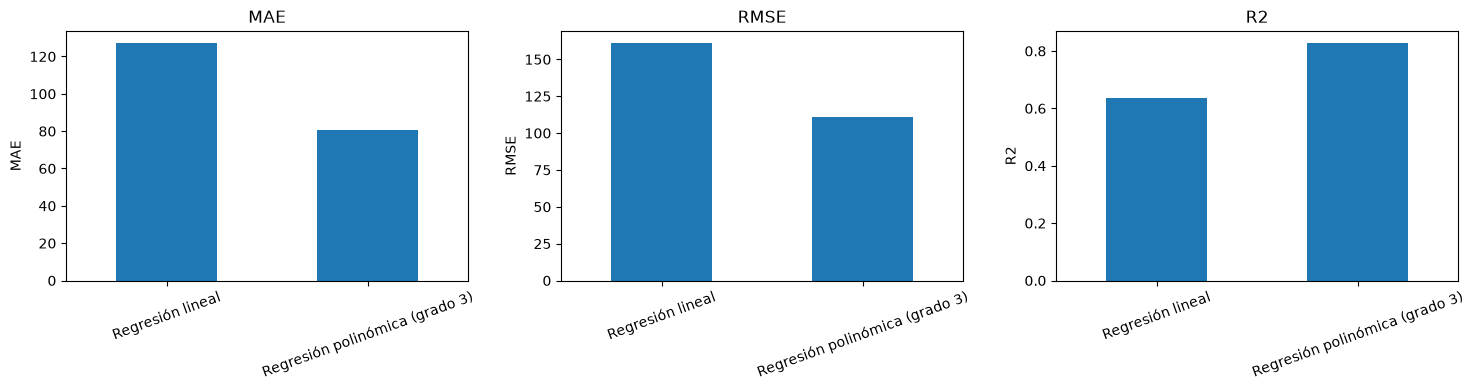

In [57]:
comparacion = pd.DataFrame({
    "Regresión lineal": evaluar_modelo(y_test, pred_test_lineal),
    f"Regresión polinómica (grado {grado_elegido})": evaluar_modelo(
        y_test,
        pred_test_polinomico
    )
}).T

display(comparacion.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metrica in zip(axes, ["MAE", "RMSE", "R2"]):

    comparacion[metrica].plot(
        kind="bar",
        ax=ax,
        legend=False
    )

    ax.set_title(metrica)
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### REGULARIZACIÓN

La regularización penaliza los coeficientes grandes para evitar el sobreajuste de modelos con muchas variables, como el polinómico: Ridge (penalización L2) reduce los coeficientes, Lasso (L1) puede llevar algunos a 0 y así elimina variables, y Elastic Net combina ambas. En la celda creamos para cada técnica un Pipeline (polinomio de grado 3, estandarización y regresor), con el escalado después del polinomio porque términos como x³ tienen escalas muy distintas y la penalización es sensible a la escala, y con GridSearchCV (validación cruzada de 5 particiones sobre train) buscamos el valor de alpha (y de l1_ratio en Elastic Net) con menor RMSE. Así obtenemos el mejor modelo regularizado de cada tipo sin usar el test.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def pipe_reg(regresor):
    return Pipeline([
        ("polinomio", PolynomialFeatures(degree=grado_elegido, include_bias=False)),
        ("escalador", StandardScaler()),
        ("regresion", regresor)
    ])

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

busqueda_ridge = GridSearchCV(
    pipe_reg(Ridge()), {"regresion__alpha": alphas},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1)
busqueda_lasso = GridSearchCV(
    pipe_reg(Lasso(max_iter=10000)), {"regresion__alpha": alphas},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1)
busqueda_elastic = GridSearchCV(
    pipe_reg(ElasticNet(max_iter=10000)),
    {"regresion__alpha": alphas, "regresion__l1_ratio": [0.2, 0.5, 0.8]},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1)

_ = busqueda_ridge.fit(X_train, y_train)
_ = busqueda_lasso.fit(X_train, y_train)
_ = busqueda_elastic.fit(X_train, y_train)

c:\Users\mikel\Desktop\RETOS\RETO 5\Equipo-Morado\retos\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.028700e+08, tolerance: 4.657e+05
  model = cd_fast.enet_coordinate_descent(
c:\Users\mikel\Desktop\RETOS\RETO 5\Equipo-Morado\retos\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.011063e+08, tolerance: 4.652e+05
  model = cd_fast.enet_coordinate_descent(
c:\Users\mikel\Desktop\RETOS\RETO 5\Equipo-Morado\retos\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, chec

Mostramos los mejores parámetros de cada búsqueda y su RMSE de validación cruzada para compararlos entre sí y con el polinómico sin regularizar (RMSE de validación del grado 3: 111,12). Ridge (alpha = 1) y Lasso (alpha = 0,01) obtienen 111,12, igual que el modelo sin regularizar, y Elastic Net queda algo peor (111,30).

In [ ]:
resultados_cv = pd.DataFrame({
    "Modelo": ["Ridge", "Lasso", "Elastic Net"],
    "Mejores parámetros": [
        busqueda_ridge.best_params_,
        busqueda_lasso.best_params_,
        busqueda_elastic.best_params_
    ],
    "RMSE validación cruzada": [
        -busqueda_ridge.best_score_,
        -busqueda_lasso.best_score_,
        -busqueda_elastic.best_score_
    ]
})

display(resultados_cv.round(3))

,Modelo,Mejores parámetros,RMSE validación cruzada
0,Ridge,{'regresion__alpha': 1},111.119
1,Lasso,{'regresion__alpha': 0.01},111.118
2,Elastic Net,"{'regresion__alpha': 0.01, 'regresion__l1_rati...",111.296


Evaluamos en test los tres modelos regularizados, limitando las predicciones a [10, 800] como en el resto de modelos, para confirmar con datos no vistos lo que indicó la validación cruzada: las tres técnicas dan un RMSE de unos 112 € y un R² de 0,824, prácticamente iguales a los del polinómico de grado 3 sin regularizar.

In [ ]:
pred_ridge = np.clip(busqueda_ridge.best_estimator_.predict(X_test), 10, 800)
pred_lasso = np.clip(busqueda_lasso.best_estimator_.predict(X_test), 10, 800)
pred_elastic = np.clip(busqueda_elastic.best_estimator_.predict(X_test), 10, 800)

comparacion_regularizacion = pd.DataFrame({
    "Ridge": evaluar_modelo(y_test, pred_ridge),
    "Lasso": evaluar_modelo(y_test, pred_lasso),
    "Elastic Net": evaluar_modelo(y_test, pred_elastic)
}).T

display(comparacion_regularizacion.round(3))

**Conclusión de la regularización:** ninguna técnica mejora de forma apreciable al polinómico de grado 3. Los valores de alpha elegidos son pequeños, es decir, el modelo casi no necesita penalización. Esto confirma que el grado 3 no sobreajusta, algo que ya indicaban la similitud entre train y test y las curvas de aprendizaje. Por tanto, mantenemos el polinómico de grado 3 sin regularizar, que es el más sencillo de explicar.

## CONCLUSIÓN: REGRESIÓN LINEAL MÚLTIPLE VS REGRESIÓN POLINÓMICA

Comparamos los dos modelos sobre el mismo conjunto de test (20 % de los datos, que no se ha usado para entrenar ni para elegir parámetros), con las predicciones limitadas a [10, 800]:


- **Capacidad predictiva:** el modelo lineal explica solo el 64 % de la variabilidad de la prima y se equivoca de media 127 € (≈ 33 % de la prima media de 385 €). El polinómico explica el 82 % y reduce el error medio a 83 € (≈ 22 %).
- **Por qué gana el polinómico:** la curva de aprendizaje del lineal muestra infraajuste (error alto que no baja con más datos) y sus residuos tienen estructura, así que la relación entre las variables y la prima no es lineal. El polinómico recoge curvaturas e interacciones.
- **Generalización:** ambos tienen errores casi iguales en entrenamiento y test, así que ninguno sobreajusta. La regularización (Ridge, Lasso y Elastic Net) no mejora al polinómico de grado 3, lo que lo confirma.
- **Explicabilidad:** el lineal es el más fácil de explicar (5 coeficientes, cada uno indica cuántos euros cambia la prima). El polinómico de grado 3 es menos directo, pero sus 55 términos se pueden listar y ordenar por peso. El grado 5, que tiene algo menos de error (RMSE de validación 105,32 frente a 111,12), exigiría 251 términos que no se pueden explicar al cliente, por eso se descarta.
- **Limitaciones:** la prima está truncada en 800 (11 % de las filas) y, aun con el polinómico, la prima de un cliente concreto conserva un error medio de unos 83 €.

**Conclusión:** el modelo polinómico de grado 3 es claramente mejor que la regresión lineal múltiple (un 30 % menos de RMSE y un 35 % menos de MAE) sin perder capacidad de generalización y manteniendo un nivel de explicabilidad aceptable. Es el modelo a usar para nuestro cliente LagunAro.

Adjuntamos nuestras predicciones y guardamos nuestro df con las nueva variable predicciones_Prima

In [ ]:
df["predicciones_Prima"] = np.clip(modelo_polinomico.predict(df[X.columns]), 10, 800)

df[["Prima", "predicciones_Prima"]].head()

In [ ]:
#df.to_csv("data/df_prediccion_prima.csv", index=False)